# Executive Summary: Hypothesis Testing Analysis
**Prepared by: Senior Data Scientist**

This report demonstrates the application of various statistical hypothesis testing methods on sample datasets. The objective is to provide a robust framework for decision-making under uncertainty, evaluating metrics ranging from conversion rates and product quality to group variances and categorical associations.

### Analytical Scope:
1. **Proportion Testing** (Two-Tailed)
2. **Mean Testing** (Left-Tailed & Two-Tailed)
3. **ANOVA Test** (Analysis of Variance)
4. **Chi-Square Test** (Test of Independence)

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Hypothesis Testing a Proportion (Two-Tailed)
**Scenario:** A company claims their new marketing campaign has a 15% conversion rate. We sample 500 users and observe 90 conversions. Does the actual conversion rate differ from 15%?

*   **Null Hypothesis ($H_0$):** The true proportion is exactly 0.15 ($p = 0.15$).
*   **Alternative Hypothesis ($H_1$):** The true proportion is not 0.15 ($p \neq 0.15$).
*   **Significance Level ($\alpha$):** 0.05

Z-statistic: 1.7461
P-value: 0.0808
Conclusion: Fail to reject the null hypothesis. No significant difference from 15%.


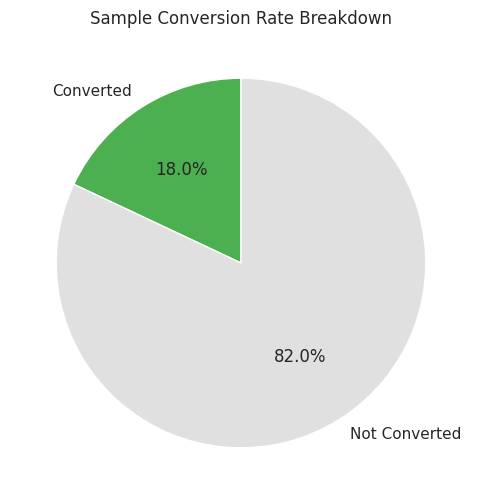

In [2]:
# Sample data
conversions = 90
sample_size = 500
null_proportion = 0.15

# Z-test for proportions
stat, p_value = proportions_ztest(count=conversions, nobs=sample_size, value=null_proportion, alternative='two-sided')

print(f"Z-statistic: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis. The conversion rate is significantly different from 15%.")
else:
    print("Conclusion: Fail to reject the null hypothesis. No significant difference from 15%.")

# Visualization
labels = ['Converted', 'Not Converted']
sizes = [conversions, sample_size - conversions]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=['#4CAF50', '#E0E0E0'], startangle=90)
plt.title('Sample Conversion Rate Breakdown')
plt.show()

## 2. Hypothesis Testing a Mean
### A. Left-Tailed Test
**Scenario:** A factory claims the average battery life is at least 50 hours. We suspect it is lower. We test 30 batteries and find an average of 48 hours with a standard deviation of 5.

*   **$H_0$:** $\mu \geq 50$
*   **$H_1$:** $\mu < 50$

### B. Two-Tailed Test
**Scenario:** A machine is supposed to fill bottles with exactly 500ml of water. We test a sample of 40 bottles.

*   **$H_0$:** $\mu = 500$
*   **$H_1$:** $\mu \neq 500$

--- Left-Tailed Test (Battery Life) ---
T-statistic: -3.5793, P-value: 0.0006
Reject H0

--- Two-Tailed Test (Bottle Volume) ---
T-statistic: -1.3456, P-value: 0.1862
Fail to reject H0


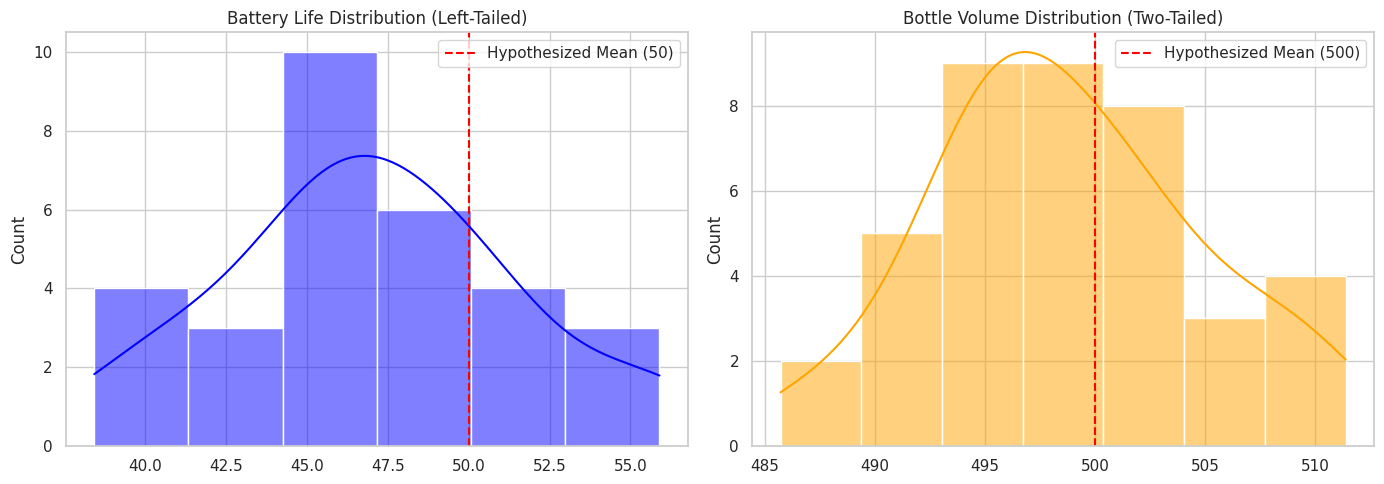

In [3]:
# --- Left-Tailed Test Data ---
np.random.seed(42)
battery_sample = np.random.normal(loc=48, scale=5, size=30)
t_stat_left, p_val_left = stats.ttest_1samp(battery_sample, popmean=50, alternative='less')

print("--- Left-Tailed Test (Battery Life) ---")
print(f"T-statistic: {t_stat_left:.4f}, P-value: {p_val_left:.4f}")
print("Reject H0" if p_val_left < 0.05 else "Fail to reject H0")

# --- Two-Tailed Test Data ---
np.random.seed(43)
bottle_sample = np.random.normal(loc=498, scale=6, size=40)
t_stat_two, p_val_two = stats.ttest_1samp(bottle_sample, popmean=500, alternative='two-sided')

print("\n--- Two-Tailed Test (Bottle Volume) ---")
print(f"T-statistic: {t_stat_two:.4f}, P-value: {p_val_two:.4f}")
print("Reject H0" if p_val_two < 0.05 else "Fail to reject H0")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(battery_sample, kde=True, ax=axes[0], color='blue')
axes[0].axvline(50, color='red', linestyle='--', label='Hypothesized Mean (50)')
axes[0].set_title('Battery Life Distribution (Left-Tailed)')
axes[0].legend()

sns.histplot(bottle_sample, kde=True, ax=axes[1], color='orange')
axes[1].axvline(500, color='red', linestyle='--', label='Hypothesized Mean (500)')
axes[1].set_title('Bottle Volume Distribution (Two-Tailed)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Case Study: ANOVA Test
**Scenario:** As a retail data scientist, you want to know if the average daily sales differ significantly across three different store locations (A, B, and C).

*   **Null Hypothesis ($H_0$):** $\mu_A = \mu_B = \mu_C$ (Average sales are equal)
*   **Alternative Hypothesis ($H_1$):** At least one store's mean sales is different.

ANOVA F-statistic: 19.8013
P-value: 2.4287e-08
Conclusion: Reject the null hypothesis. There is a significant difference in mean sales among the stores.


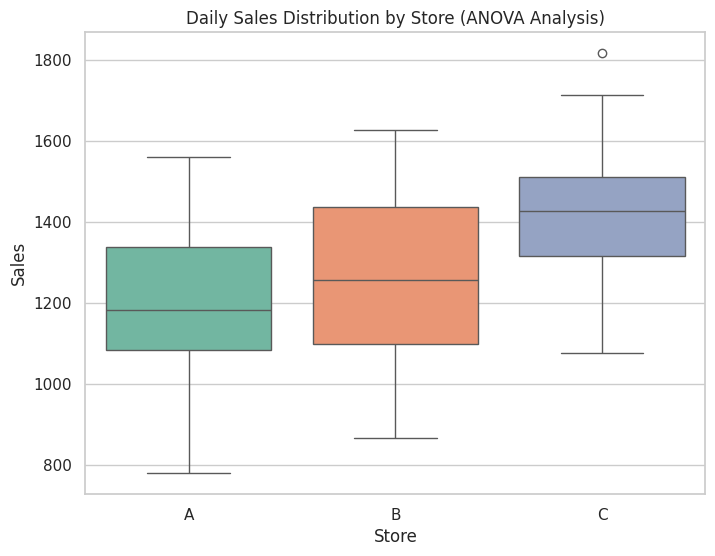

In [7]:
# Generate sample dataset for ANOVA
np.random.seed(123)
store_a = np.random.normal(loc=1200, scale=150, size=50) # Store A mean ~ 1200
store_b = np.random.normal(loc=1250, scale=180, size=50) # Store B mean ~ 1250
store_c = np.random.normal(loc=1400, scale=160, size=50) # Store C mean ~ 1400 (Higher)

# Perform One-Way ANOVA
f_stat, p_value_anova = stats.f_oneway(store_a, store_b, store_c)

print(f"ANOVA F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value_anova:.4e}")
if p_value_anova < 0.05:
    print("Conclusion: Reject the null hypothesis. There is a significant difference in mean sales among the stores.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")

# Visualization for ANOVA
store_data = pd.DataFrame({
    'Sales': np.concatenate([store_a, store_b, store_c]),
    'Store': ['A']*50 + ['B']*50 + ['C']*50
})

plt.figure(figsize=(8, 6))
sns.boxplot(x='Store', y='Sales', data=store_data, hue='Store', palette='Set2', legend=False)
plt.title('Daily Sales Distribution by Store (ANOVA Analysis)')
plt.show()

## 4. Case Study: Chi-Square Test
**Scenario:** We want to determine if there is a relationship between "Customer Subscription Type" (Basic, Premium) and "Device Preference" (Mobile, Desktop) in our platform usage data.

*   **Null Hypothesis ($H_0$):** Subscription type and device preference are independent.
*   **Alternative Hypothesis ($H_1$):** There is a dependency between the two categorical variables.

,Mobile,Desktop
Basic,150,50
Premium,60,140



Chi-Square Statistic: 79.4085
P-value: 5.0508e-19
Degrees of Freedom: 1
Conclusion: Reject H0. Subscription type and device preference are dependent (associated).


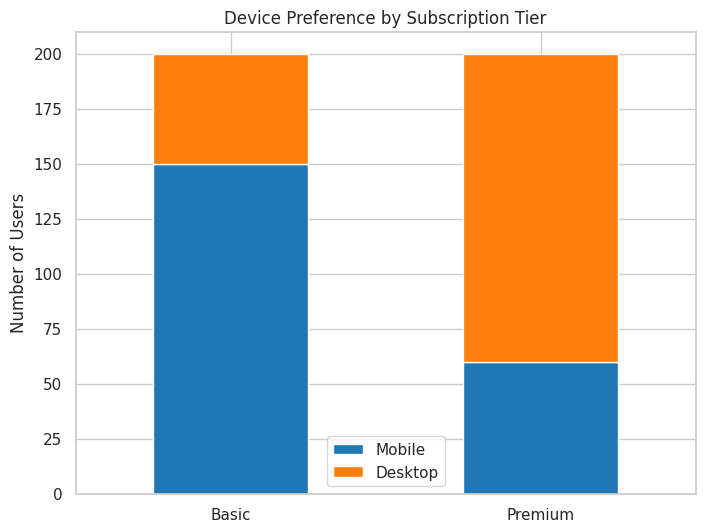

In [5]:
# Create a sample contingency table (Observed frequencies)
# Rows: Basic, Premium | Columns: Mobile, Desktop
observed_data = np.array([[150, 50],   # Basic users
                          [60, 140]])  # Premium users

chi_df = pd.DataFrame(observed_data, columns=['Mobile', 'Desktop'], index=['Basic', 'Premium'])
display(chi_df)

# Perform Chi-Square Test of Independence
chi2_stat, p_val_chi, dof, expected = stats.chi2_contingency(observed_data)

print(f"\nChi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value: {p_val_chi:.4e}")
print(f"Degrees of Freedom: {dof}")

if p_val_chi < 0.05:
    print("Conclusion: Reject H0. Subscription type and device preference are dependent (associated).")
else:
    print("Conclusion: Fail to reject H0. The variables are independent.")

# Visualization for Chi-Square
chi_df.plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], figsize=(8, 6))
plt.title('Device Preference by Subscription Tier')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.show()